<a href="https://colab.research.google.com/github/AngelinaBhowmick1/skills-review-pull-requests/blob/main/social_learning_model_tutorial_notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 2: Social Learning as Bayesian Inference

In this tutorial, we will build a very small version of the social learning model from Shafto, Goodman, & Frank (2012), focusing on the examples from the appendix: *Bob's Box* and *Tim's Toy*.

**The best way to do the tutorial is to read the Shafto paper beforehand or in parallel with the tutorial.**

You don't need to understand every single line of code (but dig in if you are curious to understand how these models work better!). The goal is to understand the central idea:

> The same evidence can support different inferences depending on their prior beliefs and how the learner thinks the evidence was generated.

A learner may interpret evidence differently when it comes from:

1. **Physical evidence**: the data are just observed (no assumptions that the agent is knowledgeable).
2. **Goal-directed action**: a knowledgeable agent is trying to make something happen.
3. **Communicative action**: a knowledgeable teacher is trying to teach the learner something.

By the end, you should understand why, in a Bayesian analysis, a teacher pressing two buttons or showing only one function of a toy can lead to much stronger conclusions than the same events observed without a teaching context.

---

## Before you start

First, **make your own copy of the notebook and put your name in the text chunk below**. To submit the assignment, you will share the link with us. **Please also submit this link on Canvas.** Make sure that the link is accessible, by either making the link accessible to anyone or (if you want to keep it private) sharing the document with me, and your TAs/PLAs:
- mzettersten@ucsd.edu
- vhennessy@ucsd.edu
- apc003@ucsd.edu
- mewolfe@ucsd.edu
- zeh012@ucsd.edu

---

## How to use this notebook

Please move slowly. Run **one cell at a time**.

Whenever you see a section called **Try it yourself**, stop and type your own example (in the dedicated code chunk).

Whenever you see **Question**, write a short answer in a comment or markdown cell before moving on.

There are also **Bonus Questions**. These are optional, but answering them can net you up to one bonus point on the assignment.

This notebook will be graded based on completion. Attempting all **Try it yourself** and **Questions** sections will net full points (just show us that you tried them out, even if you're not sure about the answer).

## Learning goals

After completing this notebook, you should be able to:

- Explain why Bayesian models combine **prior beliefs** with **likelihoods**.
- Explain why the **sampling process** matters for learning.
- Distinguish physical evidence, goal-directed action, and communicative action.
- Interpret the logic behind the Bob's Box and Tim's Toy examples.
- Use a tiny amount of Python to compute and visualize posterior probabilities.

## Please enter your name below

**Name:**

---



## Part 1: Bayesian inference in one sentence

A Bayesian learner asks:

> Which hypothesis would make the observed data most likely, given what I already believed before seeing the data?

Mathematically:

$$P(h \mid d) \propto P(d \mid h)P(h)$$

In words:

$$\text{posterior belief} \propto \text{likelihood} \times \text{prior belief}$$

Bayesian models are useful because they force us to specify the learner's assumptions: what hypotheses are possible, what was expected before "making contact" with the data, and how the data were generated.

### 1.1 Question

Imagine you see someone press two buttons (button A and button B) and a light turns on. Before doing any math, what are at least two possible explanations for what caused the light?

**Your answer:**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Helper function: convert unnormalized scores into probabilities that sum to 1

def normalize(scores):
    scores = np.array(scores, dtype=float)
    total = scores.sum()
    if total == 0:
        return scores
    return scores / total

# Helper function: make a simple bar plot

def plot_probs(labels, probs, title, ylim=(0, 1)):
    plt.figure(figsize=(6, 3.5))
    plt.bar(labels, probs)
    plt.ylim(*ylim)
    plt.ylabel("Posterior probability")
    plt.title(title)
    plt.show()

## Part 2: Bob's Box

Bob's Box has two buttons: **A** and **B**. Bob presses **both buttons** and the light turns on.

The learner considers four hypotheses:

| Hypothesis | Meaning |
|---|---|
| None | Neither button causes the light |
| A | Button A alone causes the light |
| B | Button B alone causes the light |
| A&B | Both buttons together are necessary |

For simplicity, we assume:

- All hypotheses start out equally likely.
- Causal relationships are deterministic.
- In the physical-evidence case, Bob's action is treated as randomly generated rather than chosen for a goal.

The full Bayesian equation is:

$$
P(h \mid a,e,g) = \frac{P(e \mid a,h)P(a \mid g,h)P(h)}{\sum_{h'} P(e \mid a,h')P(a \mid g,h')P(h')}
$$

Here:

- $h$ = a hypothesis about how the box works
- $a$ = Bob's action, such as pressing A, pressing B, or pressing A&B
- $e$ = the effect, here the light turning on
- $g$ = Bob's goal

For **physical evidence**, the action-selection term is uniform. In the  simplified Bob's Box model, pressing A&B is one of four possible action patterns, so:

$$P(a = \text{press A&B} \mid g,h) = 0.25$$

Because this value is the same for every hypothesis, it does not change the relative posterior probabilities. But we will keep it in the table so that Parts 2, 3, and 4 all use the same equation.

For the effect term:

| Hypothesis | P(e \ a,h) | P(a \ g,h) | Why? |
|---|---|---|---|
| None | 0 | 0.25 | If neither button causes the light, pressing A&B should not turn it on. |
| A | 1 | 0.25 | If A works, pressing A&B also turns on the light. |
| B | 1 | 0.25 | If B works, pressing A&B also turns on the light. |
| A&B | 1 | 0.25 | If both are needed, pressing A&B turns on the light. |

In [ ]:
bob_hypotheses = ["None", "A", "B", "A&B"]
bob_prior = np.array([0.25, 0.25, 0.25, 0.25])

# Observed action and effect: Bob presses both buttons -> light turns on.
# P(e | a,h): Would the light turn on after pressing A&B under each hypothesis?
bob_effect_likelihood = np.array([0, 1, 1, 1])

# P(a | g,h): In the physical-evidence case, the action is treated as randomly sampled.
# The appendix uses .25 because pressing A&B is one of four possible action patterns.
bob_action_physical = np.array([0.25, 0.25, 0.25, 0.25])

bob_physical = normalize(
    bob_prior
    * bob_effect_likelihood   # P(e | a,h)
    * bob_action_physical     # P(a | g,h)
)

pd.DataFrame({
    "hypothesis": bob_hypotheses,
    "P(e | a,h)": bob_effect_likelihood,
    "P(a | g,h)": bob_action_physical,
    "posterior": np.round(bob_physical, 3)
})

,hypothesis,"P(e | a,h)","P(a | g,h)",posterior
0,None,0,0.25,0.000
1,A,1,0.25,0.333
2,B,1,0.25,0.333
3,A&B,1,0.25,0.333


In [ ]:
plot_probs(bob_hypotheses, bob_physical, "Bob's Box: physical evidence")

### 2.1. Question

Interpret the result of the simulation. What outcome do you observe? Try to explain why the result turns out this way in your own words.

**Your answer:**

### 2.2. Try it yourself

Update the prior so that, going in, the learner has a bias that A is the most likely hypothesis:

- Prior probability of None: 0.2
- Prior probability of A: 0.4
- Prior probability of B: 0.2
- Prior probability of A&B: 0.2

Change the prior in the first code chunk. The second code chunk will compute the posterior using the same full equation.

In [ ]:
#enter the new prior here
bob_new_prior = np.array([0.25, 0.25, 0.25, 0.25]) #CURRENTLY THE OLD PRIOR, UPDATE TO THE NEW ONE ABOVE

In [ ]:
# Leave the code here unchanged.
bob_new_physical = normalize(
    bob_new_prior
    * bob_effect_likelihood
    * bob_action_physical
)

pd.DataFrame({
    "hypothesis": bob_hypotheses,
    "P(e | a,h)": bob_effect_likelihood,
    "P(a | g,h)": bob_action_physical,
    "posterior": np.round(bob_new_physical, 3)
})

,hypothesis,"P(e | a,h)","P(a | g,h)",posterior
0,None,0,0.25,0.000
1,A,1,0.25,0.333
2,B,1,0.25,0.333
3,A&B,1,0.25,0.333


### 2.3. Question
Describe the new outcome. What changed and why? *(write 1-2 sentences below before moving on)*

**Your answer:**



#### 2.4. Question

How can you change the prior above so that A&B becomes the most likely posterior hypothesis, given the same evidence? *(specify the prior below, and/or try it out by updating the prior in 2.2.!)*

**Your answer:**

## Part 3: Adding goal-directed action

Now suppose Bob is knowledgeable and his goal is simply to **turn on the light**.

We still use the full equation:

$$
P(h \mid a,e,g) = \frac{P(e \mid a,h)P(a \mid g,h)P(h)}{\sum_{h'} P(e \mid a,h')P(a \mid g,h')P(h')}
$$

The effect term $P(e \mid a,h)$ is the same as before: pressing A&B turns on the light under A, B, and A&B, but not under None.

What changes is $P(a \mid g,h)$: how likely Bob is to choose **press A&B** if his goal is to turn on the light.

| Hypothesis | P(e \ a,h) | P(a \ g,h) | Why? |
|---|---:|---:|---|
| None | 0 | 0 | No action can turn on the light. |
| A | 1 | 0.5 | A works, but A&B also works; two goal-achieving actions. |
| B | 1 | 0.5 | B works, but A&B also works; two goal-achieving actions. |
| A&B | 1 | 1 | Pressing both is the only action that works. |

This is the key idea from the paper: actions are more informative when they are chosen by a knowledgeable, goal-directed actor.

In [ ]:
# P(a | g,h): probability that Bob chooses the observed action, press A&B,
# if he knows the true hypothesis and wants to turn on the light.
bob_action_goal_directed = np.array([0, 0.5, 0.5, 1.0])

bob_goal_directed = normalize(
    bob_prior
    * bob_effect_likelihood       # P(e | a,h)
    * bob_action_goal_directed    # P(a | g,h)
)

pd.DataFrame({
    "hypothesis": bob_hypotheses,
    "P(e | a,h)": bob_effect_likelihood,
    "P(a | g,h)": bob_action_goal_directed,
    "posterior": np.round(bob_goal_directed, 3)
})

,hypothesis,"P(e | a,h)","P(a | g,h)",posterior
0,None,0,0.0,0.00
1,A,1,0.5,0.25
2,B,1,0.5,0.25
3,A&B,1,1.0,0.50


In [ ]:
plot_probs(bob_hypotheses, bob_goal_directed, "Bob's Box: goal-directed action")

### Question 3.1

In your own words, interpret the outcome. What is the new posterior belief? Why does the math work out this way?

**Your answer:**

## Part 4: Adding communicative action

Now suppose Bob is not just trying to turn on the light. Bob is trying to **teach you how the box works**.

In a **communicative** context, Bob's goal is for the learner to infer the right hypothesis. We model this by having the teacher choose actions according to:

$$
P(a \mid g,h) = \frac{P(g \mid a,h)}{\sum_{a'} P(g \mid a',h)}
$$

For teaching, $P(g \mid a,h)$ means: *if Bob chooses this action, how strongly would the learner infer the correct hypothesis?*

We will build this in two stages:

1. **One step of communicative reasoning:** Bob chooses an action based on what a literal learner would infer.
2. **Recursive communicative reasoning:** the learner and teacher repeatedly reason about one another.

In [ ]:
# Part 4A. Set up possible actions and causal structure for Bob's Box.

bob_actions = ["press A", "press B", "press A&B"]
observed_action = "press A&B"

# Rows = hypotheses: None, A, B, A&B
# Columns = actions: press A, press B, press A&B
# Entry = P(e | a, h): 1 if that action would turn on the light under that hypothesis, otherwise 0.
bob_effect_matrix = np.array([
    [0, 0, 0],  # None: no action turns on the light
    [1, 0, 1],  # A: pressing A, or A&B, turns on the light
    [0, 1, 1],  # B: pressing B, or A&B, turns on the light
    [0, 0, 1],  # A&B: only pressing both turns on the light
])

pd.DataFrame(
    bob_effect_matrix,
    index=bob_hypotheses,
    columns=bob_actions
)

,press A,press B,press A&B
None,0,0,0
A,1,0,1
B,0,1,1
A&B,0,0,1


### One step of communicative reasoning

First, imagine a **literal learner** who treats each possible action as physical evidence.

For example, if Bob presses **A&B**, the literal learner thinks A, B, and A&B are all possible. If Bob presses **A** alone, the literal learner thinks A is the only possible cause.

A helpful teacher then asks: *which action would make the learner infer the true hypothesis?* This gives us $P(a \mid g,h)$ for one step of teaching.

Finally, the learner uses the equation:

$$
P(h \mid a,e,g) = \frac{P(e \mid a,h)P(a \mid g,h)P(h)}{\sum_{h'} P(e \mid a,h')P(a \mid g,h')P(h')}
$$

In [ ]:
# Part 4B. One step of communicative reasoning.

# Literal learner: what would each possible action imply if it were just physical evidence?
literal_learner_beliefs_by_action = np.vstack([
    normalize(bob_prior * bob_effect_matrix[:, action_index])
    for action_index in range(len(bob_actions))
])

# Teacher model: P(action | communicative goal, hypothesis)
# For each true hypothesis, Bob favors actions that would make the literal learner infer that hypothesis.
bob_teacher_action_one_step = np.zeros((len(bob_hypotheses), len(bob_actions)))
for h_index in range(len(bob_hypotheses)):
    helpfulness = literal_learner_beliefs_by_action[:, h_index]
    possible_actions = bob_effect_matrix[h_index, :]
    bob_teacher_action_one_step[h_index, :] = normalize(helpfulness * possible_actions)

observed_index = bob_actions.index(observed_action)

# Learner update using the full appendix equation.
bob_communicative_one_step = normalize(
    bob_prior
    * bob_effect_matrix[:, observed_index]       # P(e | a, h)
    * bob_teacher_action_one_step[:, observed_index]  # P(a | g, h)
)

pd.DataFrame({
    "hypothesis": bob_hypotheses,
    "P(e | a,h)": bob_effect_matrix[:, observed_index],
    "P(a | g,h)": np.round(bob_teacher_action_one_step[:, observed_index], 3),
    "posterior after one communicative step": np.round(bob_communicative_one_step, 3)
})

,hypothesis,"P(e | a,h)","P(a | g,h)",posterior after one communicative step
0,None,0,0.00,0.000
1,A,1,0.25,0.167
2,B,1,0.25,0.167
3,A&B,1,1.00,0.667


### 4.1. Question

Compare the one-step communicative posterior to the goal-directed posterior from Part 3. What changed in the $P(a \mid g,h)$ column, and why does that make **A&B** more likely?

**Your answer:**

### Recursive communicative reasoning

The one-step model already makes the inference stronger. But the paper points out that communicative reasoning is **recursive**: learners reason about teachers, and teachers reason about learners (learner: "I know that you're trying to teach me, and I know that you know that I'm trying to learn from your demonstration and I know that you know that I know.....").

We can approximate this by iterating:

1. Start with a literal learner.
2. Let the teacher choose actions based on what that learner would infer.
3. Let the learner update again using the teacher's action probabilities.
4. Repeat.

Below, we first compare **1 iteration** to **5 iterations**. Then you will try larger values yourself. The table shows the posterior belief for each hypothesis after a given number of iterations.

In [ ]:
# Part 4C. Recursive communicative reasoning.

def bob_communicative_posterior(n_iterations=1, observed_action="press A&B"):
    """Compute Bob's Box communicative posterior after n rounds of recursive reasoning."""
    observed_index = bob_actions.index(observed_action)

    # Start with the literal learner: each possible action is interpreted as physical evidence.
    learner_beliefs_by_action = np.vstack([
        normalize(bob_prior * bob_effect_matrix[:, action_index])
        for action_index in range(len(bob_actions))
    ])

    for i in range(n_iterations):
        # Teacher: choose actions that would help the learner infer the true hypothesis.
        teacher_action_likelihood = np.zeros((len(bob_hypotheses), len(bob_actions)))

        for h_index in range(len(bob_hypotheses)):
            helpfulness = learner_beliefs_by_action[:, h_index]
            possible_actions = bob_effect_matrix[h_index, :]
            teacher_action_likelihood[h_index, :] = normalize(helpfulness * possible_actions)

        # Learner: update using the full appendix equation.
        learner_beliefs_by_action = np.vstack([
            normalize(
                bob_prior
                * bob_effect_matrix[:, action_index]              # P(e | a,h)
                * teacher_action_likelihood[:, action_index]      # P(a | g,h)
            )
            for action_index in range(len(bob_actions))
        ])

    return learner_beliefs_by_action[observed_index]

# Show the transition from 1 recursive iteration to 5 recursive iterations.
# UPDATE ITERATION VALUES HERE TO SEE THE EFFECT OF MORE ITERATIONS (4.2)
bob_iteration_values = [1, 5]

bob_iteration_table = pd.DataFrame({
    f"{n} iteration(s)": np.round(bob_communicative_posterior(n_iterations=n, observed_action=observed_action), 3)
    for n in bob_iteration_values
})
bob_iteration_table.insert(0, "hypothesis", bob_hypotheses)
bob_iteration_table

,hypothesis,1 iteration(s),5 iteration(s)
0,None,0.000,0.000
1,A,0.167,0.056
2,B,0.167,0.056
3,A&B,0.667,0.889


### 4.2. Try it yourself

In the code above, change `bob_iteration_values` from `[1, 5]` to `[1, 5, 10, 100, 1000]`, then rerun the cell.

What happens to the posterior for **A&B** as the number of recursive iterations increases (see the table above)?

**Your answer:**

In [ ]:
# Part 4D. Use 1000 iterations as the default communicative-action posterior for later comparisons to match paper more closely (just run the cells below)

n_iterations = 1000
bob_communicative = bob_communicative_posterior(
    n_iterations=n_iterations,
    observed_action=observed_action
)

pd.DataFrame({
    "hypothesis": bob_hypotheses,
    f"posterior after {n_iterations} iterations": np.round(bob_communicative, 3)
})

,hypothesis,posterior after 1000 iterations
0,None,0.000
1,A,0.000
2,B,0.000
3,A&B,0.999


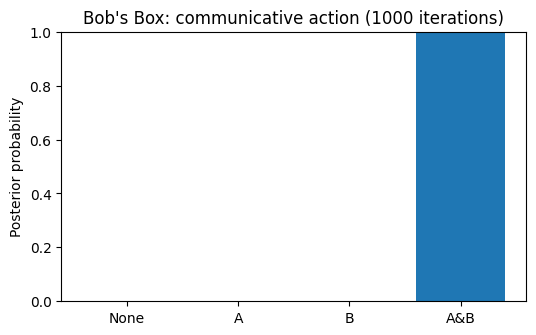

In [ ]:
plot_probs(bob_hypotheses, bob_communicative, f"Bob's Box: communicative action ({n_iterations} iterations)")

## Part 5: Compare all three contexts for Bob's Box

The physical event is identical in all three cases: Bob presses A&B and the light turns on. What changes is the assumed process that generated Bob's action.

In [ ]:
bob_results = pd.DataFrame({
    "hypothesis": bob_hypotheses,
    "Physical evidence": np.round(bob_physical, 3),
    "Goal-directed action": np.round(bob_goal_directed, 3),
    "Communicative action": np.round(bob_communicative, 3)
})

bob_results

,hypothesis,Physical evidence,Goal-directed action,Communicative action
0,None,0.000,0.00,0.000
1,A,0.333,0.25,0.000
2,B,0.333,0.25,0.000
3,A&B,0.333,0.50,0.999


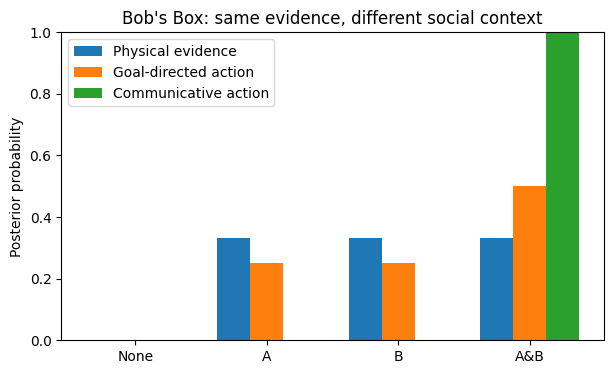

In [ ]:
contexts = ["Physical evidence", "Goal-directed action", "Communicative action"]

plt.figure(figsize=(7, 4))
x = np.arange(len(bob_hypotheses))
width = 0.25

for i, context in enumerate(contexts):
    plt.bar(x + (i - 1) * width, bob_results[context], width, label=context)

plt.xticks(x, bob_hypotheses)
plt.ylim(0, 1)
plt.ylabel("Posterior probability")
plt.title("Bob's Box: same evidence, different social context")
plt.legend()
plt.show()

### 5.1. Question

The physical event was the same in all three cases: Bob pressed A&B, and the light turned on. But the learner's conclusion changed depending on the scenario.

In one sentence, explain why the **same evidence** can lead to different conclusions in different social contexts.

**Your answer:**

## Part 6: Tim's Toy

Now consider a toy with hidden functions. Tim pulls one knob, the toy squeaks, and then Tim stops.

The learner considers three hypotheses:

| Hypothesis | Meaning |
|---|---|
| 0 | The toy has no causal functions |
| 1 | The toy has exactly one causal function |
| 2 | The toy has two causal functions |

As a starting point, all hypotheses are equally likely.

For the physical-evidence case, we again use the equation:

$$
P(h \mid a,e,g) = \frac{P(e \mid a,h)P(a \mid g,h)P(h)}{\sum_{h'} P(e \mid a,h')P(a \mid g,h')P(h')}
$$

The learner observes **one action-effect pair**: Tim performs one action and one squeak occurs.

In the physical-evidence/random-action case, the action-selection term is uniform. In the simplified Tim's Toy model, choosing the observed one-action demonstration has probability:

$$P(a = \text{show 1} \mid g,h) = \frac{1}{3}$$

for each hypothesis. The effect term is:

| Hypothesis | P(e \ a,h) | P(a \ g,h) | Why? |
|---|---:|---:|---|
| 0 | 0 | 1/3 | One squeak is impossible if the toy has no functions. |
| 1 | 1 | 1/3 | One squeak is possible if the toy has one function. |
| 2 | 1 | 1/3 | One squeak is also possible if the toy has two functions. |

Because $P(a \mid g,h)$ is uniform here, it does not distinguish $h=1$ from $h=2$. But it is still part of the full likelihood.

In [ ]:
tim_hypotheses = ["0", "1", "2"]
#UPDATE THE PRIOR IN 6.2 HERE
tim_prior = np.array([1/3, 1/3, 1/3])

# Observation: Tim demonstrates one function.
# P(e | a,h): one function is impossible if the toy has 0 functions,
# but possible if the toy has 1 or 2 functions.
tim_evidence_likelihood = np.array([0, 1, 1])

# P(a | g,h): in the physical-evidence/random-action case,
# actions are sampled uniformly at random in the simplified appendix model.
tim_action_physical = np.array([1/3, 1/3, 1/3])

tim_physical = normalize(
    tim_prior
    * tim_evidence_likelihood   # P(e | a,h)
    * tim_action_physical       # P(a | g,h)
)

pd.DataFrame({
    "number_of_functions": tim_hypotheses,
    "P(e | a,h)": tim_evidence_likelihood,
    "P(a | g,h)": np.round(tim_action_physical, 3),
    "posterior": np.round(tim_physical, 3)
})

,number_of_functions,"P(e | a,h)","P(a | g,h)",posterior
0,0,0,0.333,0.0
1,1,1,0.333,0.5
2,2,1,0.333,0.5


In [ ]:
plot_probs(tim_hypotheses, tim_physical, "Tim's Toy: physical evidence")

### 6.1. Question

In your own words, why does observing one squeak rule out the hypothesis that the toy has **0** functions, but not rule out the hypothesis that the toy has **2** functions?

**Your answer:**

### 6.2. Try it yourself

Change `tim_prior` so that the learner initially thinks complex toys probably have two functions:

- $P(h=0)=0.10$
- $P(h=1)=0.20$
- $P(h=2)=0.70$

Then rerun the physical-evidence code. What changes?

**Your answer:**

## Part 7: Goal-directed action for Tim's Toy

Now suppose Tim is knowledgeable, but his goal is simply:

> Make the toy squeak.

This is different from teaching. Tim wants to produce **one desired effect**, not necessarily reveal all of the toy's hidden functions.

We model action choice as:

$$
P(a \mid g,h) = \frac{P(g \mid a,h)}{\sum_{a'} P(g \mid a',h)}
$$

For Tim's Toy, the observed action is **show one squeak**. In our simplified goal-directed model:

| Hypothesis | P(e \ a,h) | P(a \ g,h) | Why? |
|---|---:|---:|---|
| 0 | 0 | 0 | Tim cannot make the toy squeak. |
| 1 | 1 | 0.5 | Showing one function achieves the goal. |
| 2 | 1 | 0.5 | Showing one function also achieves the goal; Tim need not reveal the second function. |

The important point is that goal-directed action does **not** distinguish $h=1$ from $h=2$ in this simplified setup.

In [ ]:
#reset the prior back to a uniform expectation (since changed in 6.2)
tim_prior = np.array([1/3, 1/3, 1/3])

# P(a | goal, hypothesis)
# action = Tim demonstrates one squeak
# This action is equally compatible
# with the 1-function and 2-function hypotheses.
tim_action_goal_directed = np.array([0, 0.5, 0.5])

tim_goal_directed = normalize(
    tim_prior
    * tim_evidence_likelihood       # P(e | a,h)
    * tim_action_goal_directed      # P(a | g,h)
)

pd.DataFrame({
    "number_of_functions": tim_hypotheses,
    "P(e | a,h)": tim_evidence_likelihood,
    "P(a | g,h)": tim_action_goal_directed,
    "posterior": np.round(tim_goal_directed, 3)
})

,number_of_functions,"P(e | a,h)","P(a | g,h)",posterior
0,0,0,0.0,0.0
1,1,1,0.5,0.5
2,2,1,0.5,0.5


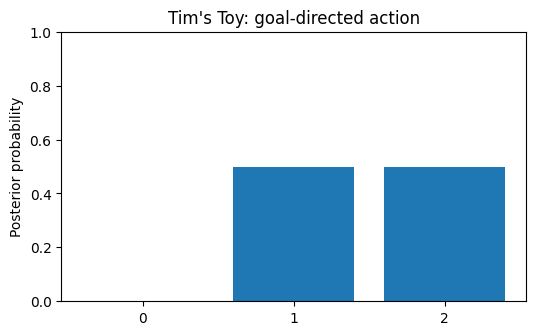

In [ ]:
plot_probs(tim_hypotheses, tim_goal_directed, "Tim's Toy: goal-directed action")

### 7.1. Question

Why does goal-directed action help in Bob's Box but not in Tim's Toy?

Hint: Think about the differences in causal structure between the two cases.

**Your answer:**

## Part 8: Communicative action for Tim's Toy

Now suppose Tim is trying to **teach you how the toy works**.

He shows one function and then stops.

In this context, stopping becomes meaningful. The learner may reason:

> If there were more functions, a helpful teacher probably would have shown them.

We use the same recursive teaching logic as before:

$$
P(a \mid g,h) = \frac{P(g \mid a,h)}{\sum_{a'} P(g \mid a',h)}
$$

For teaching, $P(g \mid a,h)$ means: *how well would this demonstration make the learner infer the true number of functions?*

We will again build this in two stages:

1. **One step of communicative reasoning:** Tim chooses a demonstration based on what a literal learner would infer.
2. **Recursive communicative reasoning:** the teacher and learner reason about each other repeatedly.

We allow three possible demonstrations:

| Demonstration | Meaning |
|---|---|
| show 0 | Tim demonstrates no functions |
| show 1 | Tim demonstrates one function |
| show 2 | Tim demonstrates two functions |

The learner observes **show 1** (i.e. Tim shows one function).

In [ ]:
# Part 8A. Set up possible demonstrations for Tim's Toy.

tim_demonstrations = ["show 0", "show 1", "show 2"]
observed_demonstration = "show 1" #UPDATE THIS VALUE AND RE-RUN EVERYTHING BELOW TO SEE THE EFFECT OF DIFFERENT DEMONSTRATIONS (8.3)

# Rows = hypotheses: 0 functions, 1 function, 2 functions
# Columns = demonstrations: show 0, show 1, show 2
# Entry = 1 if that demonstration is possible under that hypothesis.
tim_possible_demo_matrix = np.array([
    [1, 0, 0],  # 0 functions: can only show 0
    [1, 1, 0],  # 1 function: can show 0 or 1
    [1, 1, 1],  # 2 functions: can show 0, 1, or 2
])

pd.DataFrame(
    tim_possible_demo_matrix,
    index=tim_hypotheses,
    columns=tim_demonstrations
)

,show 0,show 1,show 2
0,1,0,0
1,1,1,0
2,1,1,1


### One step of communicative reasoning

First, imagine a literal learner who treats each possible demonstration as physical evidence.

- If Tim shows **0** functions, all three hypotheses remain possible.
- If Tim shows **1** function, $h=0$ is ruled out, but $h=1$ and $h=2$ remain possible.
- If Tim shows **2** functions, only $h=2$ remains possible.

A helpful teacher then chooses a demonstration based on which demonstration would make the learner infer the true number of functions.

In [ ]:
# Part 8B. One step of communicative reasoning.

# Literal learner: what would each demonstration imply as physical evidence?
literal_learner_beliefs_by_demo = np.vstack([
    normalize(tim_prior * tim_possible_demo_matrix[:, demo_index])
    for demo_index in range(len(tim_demonstrations))
])

# Teacher model: P(demonstration | communicative goal, hypothesis)
# For each true hypothesis, Tim favors demonstrations that would make the literal learner infer that hypothesis.
tim_teacher_demo_one_step = np.zeros((len(tim_hypotheses), len(tim_demonstrations)))
for h_index in range(len(tim_hypotheses)):
    helpfulness = literal_learner_beliefs_by_demo[:, h_index]
    possible_demonstrations = tim_possible_demo_matrix[h_index, :]
    tim_teacher_demo_one_step[h_index, :] = normalize(helpfulness * possible_demonstrations)

observed_demo_index = tim_demonstrations.index(observed_demonstration)

tim_communicative_one_step = normalize(
    tim_prior
    * tim_possible_demo_matrix[:, observed_demo_index]       # P(e | a,h), simplified as compatibility
    * tim_teacher_demo_one_step[:, observed_demo_index]      # P(a | g,h)
)

pd.DataFrame({
    "number_of_functions": tim_hypotheses,
    "P(e | a,h)": tim_possible_demo_matrix[:, observed_demo_index],
    "P(a | g,h), one-step teacher": np.round(tim_teacher_demo_one_step[:, observed_demo_index], 3),
    "posterior after one communicative step": np.round(tim_communicative_one_step, 3)
})

,number_of_functions,"P(e | a,h)","P(a | g,h), one-step teacher",posterior after one communicative step
0,0,0,0.000,0.000
1,1,1,0.600,0.688
2,2,1,0.273,0.312


### 8.1. Question

Why does the one-step communicative model already favor **1 function** over **2 functions** after Tim shows one function and stops?

**Your answer:**

### Recursive communicative reasoning

As with Bob's Box, the one-step model is only the beginning. We can iterate teacher-learner reasoning.

Below, we first compare **1 iteration** to **5 iterations**. Then you will try larger values yourself.

In [ ]:
# Part 8C. Recursive communicative reasoning.

def tim_communicative_posterior(n_iterations=1, observed_demonstration="show 1"):
    """Compute Tim's Toy communicative posterior after n rounds of recursive reasoning."""
    observed_demo_index = tim_demonstrations.index(observed_demonstration)

    # Start with the literal learner.
    learner_beliefs_by_demo = np.vstack([
        normalize(tim_prior * tim_possible_demo_matrix[:, demo_index])
        for demo_index in range(len(tim_demonstrations))
    ])

    for i in range(n_iterations):
        # Teacher: choose demonstrations that would help the learner infer the true hypothesis.
        teacher_demo_likelihood = np.zeros((len(tim_hypotheses), len(tim_demonstrations)))

        for h_index in range(len(tim_hypotheses)):
            helpfulness = learner_beliefs_by_demo[:, h_index]
            possible_demonstrations = tim_possible_demo_matrix[h_index, :]
            teacher_demo_likelihood[h_index, :] = normalize(helpfulness * possible_demonstrations)

        # Learner: update using the full appendix equation.
        learner_beliefs_by_demo = np.vstack([
            normalize(
                tim_prior
                * tim_possible_demo_matrix[:, demo_index]       # P(e | a,h), simplified as compatibility
                * teacher_demo_likelihood[:, demo_index]        # P(a | g,h)
            )
            for demo_index in range(len(tim_demonstrations))
        ])

    return learner_beliefs_by_demo[observed_demo_index]

# Show the transition from 1 recursive iteration to 5 recursive iterations.
#UPDATE THE NUMBER OF ITERATIONS HERE
tim_iteration_values = [1, 5]

tim_iteration_table = pd.DataFrame({
    f"{n} iteration(s)": np.round(tim_communicative_posterior(n_iterations=n, observed_demonstration=observed_demonstration), 3)
    for n in tim_iteration_values
})
tim_iteration_table.insert(0, "number_of_functions", tim_hypotheses)
tim_iteration_table

,number_of_functions,1 iteration(s),5 iteration(s)
0,0,0.000,0.000
1,1,0.688,0.869
2,2,0.312,0.131


### 8.2. Try it yourself

In the code above, change `tim_iteration_values` from `[1, 5]` to `[1, 5, 10, 100, 1000]`, then rerun the cell.

What happens to the posterior for **1 function** as the number of recursive iterations increases?

**Your answer:**

### 8.3. Try it yourself

Change `observed_demonstration` from `"show 1"` to `"show 2"`, then rerun the Part 8 code .

What should the learner infer if a helpful teacher demonstrates two functions? Does this result match your intuitions?

**Your answer:**

In [ ]:
# Part 8D. Use 1000 iterations as the default communicative-action posterior for later comparisons and make sure observed_demonstration is "show 1"
# DON'T EDIT THIS PART! (it just puts us back at the main outcome of the model/ communicative action scenario in the paper)

tim_n_iterations = 1000
observed_demonstration = "show 1"
tim_communicative = tim_communicative_posterior(
    n_iterations=tim_n_iterations,
    observed_demonstration=observed_demonstration
)

pd.DataFrame({
    "number_of_functions": tim_hypotheses,
    f"posterior after {tim_n_iterations} iterations": np.round(tim_communicative, 3)
})

,number_of_functions,posterior after 1000 iterations
0,0,0.000
1,1,0.999
2,2,0.001


In [ ]:
plot_probs(tim_hypotheses, tim_communicative, f"Tim's Toy: communicative action ({tim_n_iterations} iterations)")

## Part 9: Compare all three contexts for Tim's Toy

Make sure to run the code (PART 8D) with one observed demonstration before this final comparison (`observed_demonstration="show 1"`).

In [ ]:
tim_results = pd.DataFrame({
    "number_of_functions": tim_hypotheses,
    "Physical evidence": np.round(tim_physical, 3),
    "Goal-directed action": np.round(tim_goal_directed, 3),
    "Communicative action": np.round(tim_communicative, 3)
})

tim_results

In [ ]:
plt.figure(figsize=(7, 4))
x = np.arange(len(tim_hypotheses))
width = 0.25

for i, context in enumerate(contexts):
    plt.bar(x + (i - 1) * width, tim_results[context], width, label=context)

plt.xticks(x, tim_hypotheses)
plt.ylim(0, 1)
plt.xlabel("Number of functions")
plt.ylabel("Posterior probability")
plt.title("Tim's Toy: same evidence, different social context")
plt.legend()
plt.show()

### 9.1. Question

Compare the three Tim's Toy posteriors. Which context leads to the strongest belief that there is exactly one function? Why?

**Your answer:**

## Part 10: Connecting back to the big idea

The model highlights a general principle:

> Learners do not only learn from data. They also learn from assumptions about how the data were selected.

This connects to a broader Bayesian framing (check out Perfors et al. in the references): the same observation can support different inferences under different generative processes. In a teaching context, data may be intentionally chosen to be useful, which can make learning efficient on the one hand, but can also limit exploration on the other.

### 10.1. Final Questions

In 2–3 sentences, explain how this model helps explain why children can learn so much from other people.

**Your answer:**

In 2-3 sentences, describe a real-life learning situation where the same action might mean something different depending on whether it was accidental, goal-directed, or communicative.

**Your answer:**

## Bonus Question 1 (Optional): Sequential Bayesian updating in Bob's Box

So far, the learner has observed one event. In real learning, evidence often arrives over time.

In this bonus exercise, you will step through multiple observations in **Bob's Box** using the **goal-directed action** model.

Assume Bob is knowledgeable and wants to turn on the light. Each time Bob presses A&B and the light turns on, the full likelihood is:

$$
P(e \mid a,h)P(a \mid g,h)
$$

| Hypothesis | P(e \ a,h) | P(a \ g,h) | Full likelihood | Why? |
|---|---:|---:|---:|---|
| None | 0 | 0 | 0 | No button causes the light |
| A | 1 | 0.5 | 0.5 | A&B works, but A alone would also work |
| B | 1 | 0.5 | 0.5 | A&B works, but B alone would also work |
| A&B | 1 | 1.0 | 1.0 | A&B is the only action that works |

Your goal is to update the posterior after each observation and use the previous posterior as the next prior.

### Bonus Question 1.1. Predict first

Before running the code, what do you expect will happen after seeing Bob press A&B several times in a row?

**Your answer:**

In [ ]:
# Bonus 1B. Starter code: define the likelihood for one observation.
# You can edit these values to explore different assumptions.

bonus_p_e_given_a_h = bob_effect_likelihood
bonus_p_a_given_g_h = bob_action_goal_directed
bonus_likelihood_press_AB = bonus_p_e_given_a_h * bonus_p_a_given_g_h

pd.DataFrame({
    "hypothesis": bob_hypotheses,
    "P(e | a,h)": bonus_p_e_given_a_h,
    "P(a | g,h)": bonus_p_a_given_g_h,
    "full likelihood": bonus_likelihood_press_AB
})

### One observation

Start with the prior and update after **one** observation of Bob pressing A&B and the light turning on.

The code is written out so you can see the full Bayesian update.

In [ ]:
# Bonus 1C. Starter code: update once.

current_belief = bob_prior.copy()

current_belief = normalize(current_belief * bonus_likelihood_press_AB)

pd.DataFrame({
    "hypothesis": bob_hypotheses,
    "posterior after 1 observation": np.round(current_belief, 3)
})

### Two observations

Now update twice. Notice that the posterior from the first observation becomes the prior for the second observation.

In [ ]:
# Bonus 1D. Starter code: update twice.
# Try editing n_observations to 3, 5, or 10.

n_observations = 2
current_belief = bob_prior.copy()

for observation_number in range(1, n_observations + 1):
    current_belief = normalize(current_belief * bonus_likelihood_press_AB)

pd.DataFrame({
    "hypothesis": bob_hypotheses,
    f"posterior after {n_observations} observations": np.round(current_belief, 3)
})

### Bonus Question 1.2. Updating across multiple observations over time

Now store the posterior after each observation so you can see the trajectory over time.

**Try it yourself:** Edit `n_observations` to try 3, 5, 10, or 20 observations.

In [ ]:
# Bonus 1E. Starter code: update repeatedly and store the history.

#UPDATE THE NUMBER OF OBSERVATIONS BELOW
n_observations = 2
current_belief = bob_prior.copy()
history = []

for observation_number in range(1, n_observations + 1):
    current_belief = normalize(current_belief * bonus_likelihood_press_AB)

    history.append({
        "observation": observation_number,
        "None": current_belief[0],
        "A": current_belief[1],
        "B": current_belief[2],
        "A&B": current_belief[3]
    })

bonus_history = pd.DataFrame(history)
bonus_history.round(3)

In [ ]:
# plot of the sequential update.
plt.figure(figsize=(7, 4))
for hypothesis in bob_hypotheses:
    plt.plot(bonus_history["observation"], bonus_history[hypothesis], marker="o", label=hypothesis)

plt.ylim(0, 1)
plt.xlabel("Observation number")
plt.ylabel("Posterior probability")
plt.title("Sequential updating in Bob's Box")
plt.legend()
plt.show()

### Bonus Question 1.3. Interpret

What happens to the posterior for **A&B** across observations? Why does repeated evidence make the posterior sharper?

**Your answer:**

How many repeated observations does it take before the posterior for **A&B** is very close to 1?

**Your answer:**

## Bonus Question 2 (Optional)

Modify one line of code below so that the learner starts with a stronger prior belief that complex toys usually have **two** functions. How does that change the physical-evidence result?

**Your answer:**

In [ ]:
# BONUS: Try changing these numbers.
# They should sum to 1.
bonus_tim_prior = np.array([1/3, 1/3, 1/3])

bonus_tim_physical = normalize(
    bonus_tim_prior
    * tim_evidence_likelihood
    * tim_action_physical
)

pd.DataFrame({
    "number_of_functions": tim_hypotheses,
    "posterior_after_one_observed_function": np.round(bonus_tim_physical, 3)
})

In [ ]:
plot_probs(tim_hypotheses, bonus_tim_physical, "Bonus: change the prior")

## References

- Shafto, P., Goodman, N. D., & Frank, M. C. (2012). Learning from others: The consequences of psychological reasoning for human learning. *Perspectives on Psychological Science, 7*(4), 341-351.
- Perfors, A., Tenenbaum, J. B., Griffiths, T. L., & Xu, F. (2011). *A tutorial introduction to Bayesian models of cognitive development*. *Cognition, 120*, 302-321.